In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

De un proyecto se dispone del grafo PERT (sin tiempos) y de la duración de cada actividad (en semanas), que se adjuntan.

In [4]:
pregunta_1 = "1. Lea del grafo el cuadro de prelaciones inmediatas. ¿Qué prelaciones aporta cada actividad ficticia?  "
pregunta_2 = "2. Calcule el calendario (inicios y fines más tempranos y más tardíos, holguras) y construya el diagrama de Gantt de inicios más tempranos, dibujando una flecha por cada prelación inmediata.  "
pregunta_3 = "3. Marque el camino crítico sobre el Gantt. ¿Qué actividades tienen hueco entre su fin y el inicio de todas sus sucesoras, y cuánto? Relaciónelo con la holgura libre.  "
pregunta_4 = "4. Dibuje el Gantt de inicios más tardíos. ¿Cuánto se ha desplazado cada actividad respecto al anterior? Relaciónelo con la holgura total.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Lea del grafo el cuadro de prelaciones inmediatas. ¿Qué prelaciones aporta cada actividad ficticia?  

2. Calcule el calendario (inicios y fines más tempranos y más tardíos, holguras) y construya el diagrama de Gantt de inicios más tempranos, dibujando una flecha por cada prelación inmediata.  

3. Marque el camino crítico sobre el Gantt. ¿Qué actividades tienen hueco entre su fin y el inicio de todas sus sucesoras, y cuánto? Relaciónelo con la holgura libre.  

4. Dibuje el Gantt de inicios más tardíos. ¿Cuánto se ha desplazado cada actividad respecto al anterior? Relaciónelo con la holgura total.  

In [5]:
#| tbl-cap: "Duración de las actividades"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 5       ),
    ('B'     , '---'      , 4       ),
    ('C'     , '---'      , 3       ),
    ('D'     , 'B,C'      , 3       ),
    ('E'     , 'D'        , 8       ),
    ('F'     , 'A,D'      , 5       ),
    ('G'     , 'E'        , 7       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado[['duration']]

,duration
activity,
A,5
B,4
C,3
D,3
E,8
F,5
G,7


El proyecto corresponde a la producción de un cortometraje; las actividades son las siguientes (las duraciones del cuadro están en días).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Guion definitivo',
    'B': 'Casting',
    'C': 'Localizaciones y permisos',
    'D': 'Diseño de vestuario y atrezo',
    'E': 'Plan de rodaje',
    'F': 'Ensayos con los actores',
    'G': 'Rodaje de exteriores',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Guion definitivo
B,Casting
C,Localizaciones y permisos
D,Diseño de vestuario y atrezo
E,Plan de rodaje
F,Ensayos con los actores
G,Rodaje de exteriores


In [7]:
_proyecto = PredecessorTable.from_dataframe_of_strings(datos_enunciado, activity='activity', predecessor='predecessor').create_project()

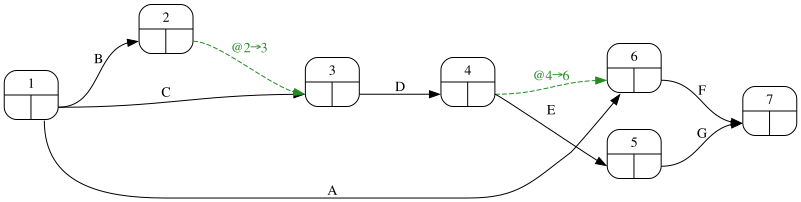

In [8]:
#| fig-cap: "Grafo PERT del proyecto"
#| label: fig-grafoEnunciado
_proyecto.pert(durations=False, ranksep=1)

# Resolución

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. Lea del grafo el cuadro de prelaciones inmediatas. ¿Qué prelaciones aporta cada actividad ficticia?  

Cada arco es una actividad: sus predecesoras inmediatas son los arcos que llegan a su nodo inicial. Si llega una ficticia, se sigue hacia atrás hasta las actividades reales que la originan: la ficticia «transporta» esas prelaciones sin ser una actividad.

In [10]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
datos_proyecto[['predecessor', 'duration']]

,predecessor,duration
activity,,
A,---,5
B,---,4
C,---,3
D,"B,C",3
E,D,8
F,"A,D",5
G,E,7


In [11]:
for d in proyecto.dummies:
    i, j = [(u, v) for u, v, dd in proyecto.pert_graph.edges(data=True) if dd['activity'] == d][0]
    origen = [dd['activity'] for _, _, dd in proyecto.pert_graph.in_edges(i, data=True)]
    destino = [dd['activity'] for _, _, dd in proyecto.pert_graph.out_edges(j, data=True)]
    print(f'{d}: lleva la prelación de {", ".join(origen)} hacia {", ".join(destino)}')

@2→3: lleva la prelación de B hacia D
@4→6: lleva la prelación de D hacia F


## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. Calcule el calendario (inicios y fines más tempranos y más tardíos, holguras) y construya el diagrama de Gantt de inicios más tempranos, dibujando una flecha por cada prelación inmediata.  

In [13]:
#| tbl-cap: "Calendario y holguras"
#| label: tbl-calendario
calendario = proyecto.calendar(datos_proyecto['duration'])
calendario

,inicio_mas_temprano,inicio_mas_tardio,fin_mas_temprano,fin_mas_tardio,H_libre,H_independiente,H_total,duracion
activity,,,,,,,,
A,0,12,5,17,2,2,12,5
B,0,0,4,4,0,0,0,4
C,0,1,3,4,1,1,1,3
D,4,4,7,7,0,0,0,3
E,7,7,15,15,0,0,0,8
F,7,17,12,22,10,0,10,5
G,15,15,22,22,0,0,0,7


In [14]:
#| tbl-cap: "Cálculo paso a paso de las fechas"
#| label: tbl-fechasPaso
detalle_holguras(calendario, prelaciones)[['ES = máx EF pred.', 'EF = ES + d', 'LF = mín LS suc.', 'LS = LF − d']]

,ES = máx EF pred.,EF = ES + d,LF = mín LS suc.,LS = LF − d
actividad,,,,
A,inicial → 0,0 + 5 = 5,mín(F: 17) = 17,17 − 5 = 12
B,inicial → 0,0 + 4 = 4,mín(D: 4) = 4,4 − 4 = 0
C,inicial → 0,0 + 3 = 3,mín(D: 4) = 4,4 − 3 = 1
D,"máx(B: 4, C: 3) = 4",4 + 3 = 7,"mín(E: 7, F: 17) = 7",7 − 3 = 4
E,máx(D: 7) = 7,7 + 8 = 15,mín(G: 15) = 15,15 − 8 = 7
F,"máx(A: 5, D: 7) = 7",7 + 5 = 12,final → 22,22 − 5 = 17
G,máx(E: 15) = 15,15 + 7 = 22,final → 22,22 − 7 = 15


Cada barra empieza en el inicio más temprano y dura lo que la actividad; las flechas unen el fin de cada predecesora con el inicio de su sucesora (en rojo, entre actividades críticas).

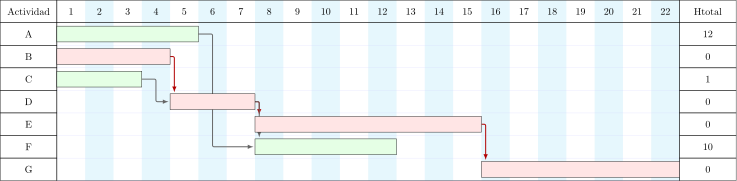

In [15]:
#| fig-cap: "Gantt de inicios más tempranos (última columna: holgura total)"
#| label: fig-ganttTemprano
_g, _dibujo = proyecto.gantt(datos_proyecto, 'duration', holguras=True, tikz=True, params=dict(inner_text=None, **GANTT_PARAMS))
pinta_tikz(_dibujo)

## Apartado 3

In [16]:
display(Markdown(pregunta_3))

3. Marque el camino crítico sobre el Gantt. ¿Qué actividades tienen hueco entre su fin y el inicio de todas sus sucesoras, y cuánto? Relaciónelo con la holgura libre.  

In [17]:
criticas = calendario.index[calendario['H_total'] == 0].tolist()
con_hueco = calendario[calendario['H_libre'] > 0]
Markdown(f'''Camino crítico (flechas rojas, barras sin hueco): {", ".join(criticas)}. Tienen hueco hasta todas sus sucesoras: {", ".join(f"{a} ({int(h)} semanas)" for a, h in con_hueco["H_libre"].items())}; ese hueco es exactamente la holgura libre (mín ES de las sucesoras − EF).''')

Camino crítico (flechas rojas, barras sin hueco): B, D, E, G. Tienen hueco hasta todas sus sucesoras: A (2 semanas), C (1 semanas), F (10 semanas); ese hueco es exactamente la holgura libre (mín ES de las sucesoras − EF).

## Apartado 4

In [18]:
display(Markdown(pregunta_4))

4. Dibuje el Gantt de inicios más tardíos. ¿Cuánto se ha desplazado cada actividad respecto al anterior? Relaciónelo con la holgura total.  

En el Gantt tardío cada barra empieza en su inicio más tardío. No basta con retrasar cada actividad su holgura total (la holgura de una cadena es compartida: si la gasta la predecesora ya no la tiene la sucesora); lo que se hace es insertar delante de cada actividad una espera 💤 igual a su inicio más tardío menos el fin más tardío de sus predecesoras, y volver a calcular.

In [19]:
filas = {}
for a, fila in datos_proyecto.iterrows():
    ps = sorted(prelaciones.immediate_predecessor[a])
    espera = int(calendario.loc[a, 'inicio_mas_tardio'] - (calendario.loc[ps, 'fin_mas_tardio'].max() if ps else 0))
    if espera > 0:
        filas['💤' + a] = {'predecessor': fila['predecessor'], 'duration': espera}
        filas[a] = {'predecessor': '💤' + a, 'duration': int(fila['duration'])}
    else:
        filas[a] = {'predecessor': fila['predecessor'], 'duration': int(fila['duration'])}
datos_tardio = pd.DataFrame(filas).T; datos_tardio.index.name = 'activity'; datos_tardio['duration'] = datos_tardio['duration'].astype(int)
proyecto_tardio = PredecessorTable.from_dataframe_of_strings(datos_tardio, activity='activity', predecessor='predecessor').create_project()
esperas = datos_tardio.loc[datos_tardio.index.str.startswith('💤'), 'duration']
desplazamiento = (proyecto_tardio.calendar(datos_tardio['duration']).loc[datos_proyecto.index, 'inicio_mas_temprano'] - calendario['inicio_mas_temprano'])
pd.DataFrame({'espera insertada': esperas.rename(index=lambda x: x[1:]).reindex(datos_proyecto.index).fillna(0).astype(int),
              'desplazamiento respecto al Gantt temprano': desplazamiento.astype(int), 'H_total': calendario['H_total']}).T

activity,A,B,C,D,E,F,G
espera insertada,12,0,1,0,0,0,0
desplazamiento respecto al Gantt temprano,12,0,1,0,0,10,0
H_total,12,0,1,0,0,10,0


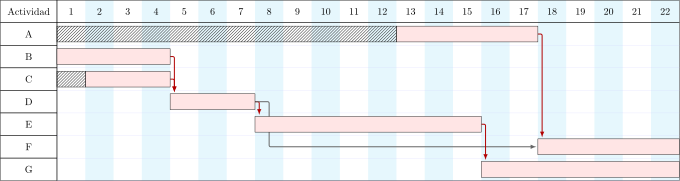

In [20]:
#| fig-cap: "Gantt de inicios más tardíos (las filas 💤 son las esperas)"
#| label: fig-ganttTardio
_g, _dibujo = proyecto_tardio.gantt(datos_tardio, 'duration', holguras=False, tikz=True, params=dict(inner_text=None, **GANTT_PARAMS))
pinta_tikz(_dibujo)

El desplazamiento de cada barra respecto al Gantt temprano es su holgura total (LS − ES), pero la espera insertada es menor cuando una predecesora ya ha consumido parte de esa holgura. Las críticas no se mueven y el fin del proyecto no cambia; en el Gantt tardío no queda hueco entre ninguna actividad y sus sucesoras: toda la holgura está gastada.